In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dataclasses import dataclass, field, asdict

import torch
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
)

In [ ]:
import sys
import os
import cv2
from pathlib import Path
sys.path.insert(0, str(Path().resolve().parent.parent.parent))

# Now your imports will work
from assessment.vIAbility.data.dataset import build_labels, load_metadata, parse_video_name
from config.config import SEED, PARAM_GRID, PATH_DATASET

In [109]:
class FEMIDataset:
    def __init__(self, files: list[str], labels: list[int]):
        self.files  = files
        self.labels = labels

    def __len__(self) -> int:
        return len(self.files)

    def __getitem__(self, idx: int):
        data = torch.load(self.files[idx], map_location="cpu", weights_only=True)
        filename = os.path.basename(self.files[idx])
        x    = data["embeddings"].float()   # (T, embed_dim)
        mask = data["mask"].bool()          # (T,)  True = valid frame
        y    = torch.tensor(self.labels[idx], dtype=torch.float32)
        return filename, x, mask, y

def build_datasets(
    feature_dir: str,
    excel_path:  str,
    test_size = 0.2,
    seed= SEED,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    df        = pd.read_excel(excel_path)
    all_files = sorted([os.path.join(feature_dir, f)for f in os.listdir(feature_dir) if f.endswith(".pt")])
    namefiles = [os.path.basename(f) for f in all_files]
    labels    = build_labels(namefiles, df)

    train_files, val_files, y_train, y_val = train_test_split(
        all_files, labels,
        test_size=test_size,
        stratify=labels,
        random_state=seed,
    )

    train_dataset = FEMIDataset(train_files, y_train)
    val_dataset   = FEMIDataset(val_files, y_val)
    X_train_files, X_test_files = [], []
    X_train, mask_train, y_train = [], [], []
    X_val, mask_val, y_val = [], [], []
    for i in range(len(train_dataset)):
        filename, x, mask, y = train_dataset[i]
        X_train_files.append(filename)
        X_train.append(x)
        mask_train.append(mask)
        y_train.append(y)
    for i in range(len(val_dataset)):
        filename, x, mask, y = val_dataset[i]
        X_test_files.append(filename)
        X_val.append(x)
        mask_val.append(mask)
        y_val.append(y)
    X_train = torch.stack(X_train)        # (N_train, T, embed_dim)
    mask_train = torch.stack(mask_train)  # (N_train, T)
    y_train = torch.stack(y_train)        # (N_train,)
    X_val = torch.stack(X_val)            # (N_val, T, embed_dim)
    mask_val = torch.stack(mask_val)      # (N_val, T)
    y_val = torch.stack(y_val)            # (N_val,)


    return (X_train_files, X_train, mask_train, y_train), (X_test_files, X_val, mask_val, y_val)

In [ ]:
%cd ../../../

/home/mvillota/Documentos/Tesis/EmbryoDev_Assess


In [14]:
feature_dir = os.path.join(PATH_DATASET, "Oslo_processed/femi_features")
excel_path = os.path.join(PATH_DATASET, "Oslo_processed/Oslo_completo.xlsx")

In [111]:
(train_files, X_train, mask_train, y_train), (X_test_files, X_val, mask_val, y_val) = build_datasets(feature_dir, excel_path, 0.2, SEED)

In [112]:
def tensors_to_lists(X, mask):
    return list(X), list(mask)

X_train, mask_train = tensors_to_lists(X_train, mask_train)
X_val, mask_val = tensors_to_lists(X_val, mask_val)

In [113]:
X_train[0].shape

torch.Size([300, 1024])

CADA VIDEO CODIFICADO COMO 300 FRAMES Y CADA FRAME ESTÁ CODIFICADO CON 1024 FEATURES

In [ ]:
X_train[0][0]

tensor([ 0.0454,  0.0581,  0.0363,  ..., -0.0284,  0.1217,  0.0757])

In [114]:
for i in range(300):
    if len(np.unique([m[i] for m in mask_train])) <2:
        print(i)
        break

214


Hasta el frame 214 hay trues

In [115]:
X_train = [X[:214] for X in X_train]
y_train = y_train
X_train_mask = [mask[:214] for mask in mask_train]

X_test = [X[:214] for X in X_val]
y_test = y_val  
X_test_mask = [mask[:214] for mask in mask_val]

In [ ]:
def get_frame(excel_path, video_file, t):
    df = load_metadata(excel_path)
    vid_id, well = parse_video_name(video_file)
    rows = df[(df["ID"] == vid_id) & (df["Well"] == well)]
    tse        = rows["Tse"].iloc[0]
    frame_hour = rows["frame_hour"].iloc[0]
    frame_idx = int((t - tse) * frame_hour)
    return frame_idx

In [119]:
def image_frame(file,excel_path, t=0):
    video_path = os.path.join(PATH_DATASET, "Oslo_processed/videos/", file.replace(".pt", ".mp4"))
    cap = cv2.VideoCapture(video_path)
    frame_idx = get_frame(excel_path, file, t)
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    _, image = cap.read()
    cap.release()
    return image

In [124]:
frame1 = {'tensores':[], 'labels':[]}
for i in range(len(X_train)):
    if X_train_mask[i][0]:  # Solo consideramos los frames válidos
        frame1['tensores'].append(X_train[i][0].numpy())
        frame1['labels'].append(y_train[i].item())

In [130]:
def frame_ext(X_train, X_train_mask, y_train, t=0):
    frame_data = {'tensores':[], 'labels':[]}
    for i in range(len(X_train)):
        if X_train_mask[i][t]:  # Solo consideramos los frames válidos
            frame_data['tensores'].append(X_train[i][t].numpy())
            frame_data['labels'].append(y_train[i].item())
    return frame_data

In [125]:
pca = PCA(n_components=30)
pca.fit(frame1['tensores'])
print(pca.explained_variance_ratio_)

[4.34624076e-01 1.42654463e-01 8.60679506e-02 4.50248664e-02
 3.89490959e-02 3.53900714e-02 2.71063154e-02 2.30758230e-02
 1.89060430e-02 1.82211268e-02 1.47513941e-02 1.20779205e-02
 1.09615542e-02 1.03870596e-02 9.10025373e-03 8.29267588e-03
 8.13760929e-03 7.43904781e-03 6.52845568e-03 6.22222785e-03
 5.27907801e-03 4.96566500e-03 4.90510070e-03 4.48508823e-03
 4.23364385e-03 3.38525618e-03 3.19840931e-03 2.88875898e-03
 2.74097029e-03 3.24142290e-31]


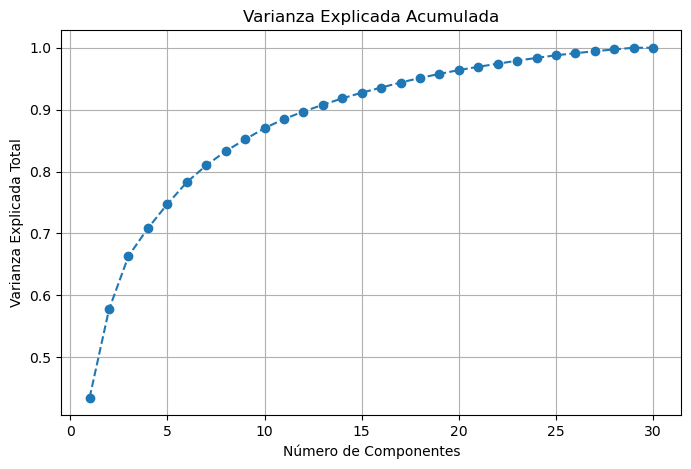

In [126]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pca.explained_variance_ratio_) + 1), 
         np.cumsum(pca.explained_variance_ratio_), marker='o', linestyle='--')

plt.title('Varianza Explicada Acumulada')
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Explicada Total')
plt.grid()
plt.show()

In [127]:
def plot_pca(frame):
    pca = PCA(n_components=2)
    pca.fit(frame['tensores'])
    print(pca.explained_variance_ratio_)

    color = ['red' if label == 1 else 'blue' for label in frame['labels']]
    X_pca = pca.transform(frame['tensores'])

    plt.figure(figsize=(8, 6))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=color, alpha=0.7)
    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} varianza)')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} varianza)')
    plt.title('Proyección de los datos en los dos primeros componentes')
    plt.grid()
    plt.show()

[0.3393335  0.27235574]


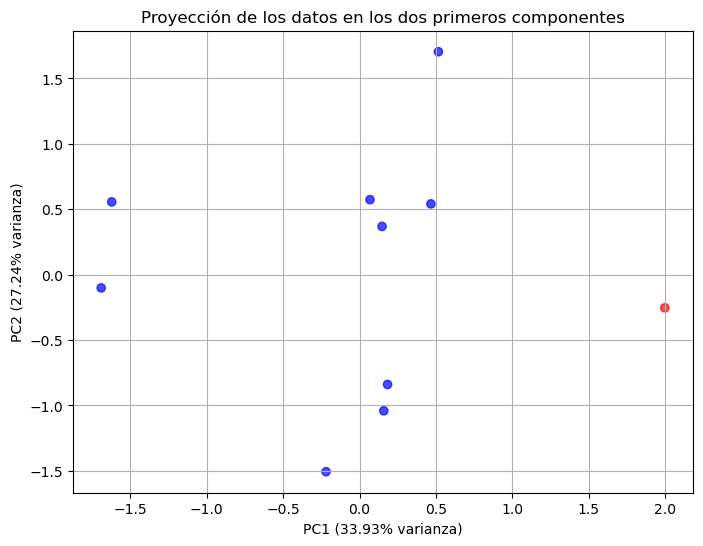

In [134]:
frame_data = frame_ext(X_train, X_train_mask, y_train, t=121)
plot_pca(frame_data)

In [133]:
frame_data['labels'][4]

1.0

In [137]:
frame_ext(X_train, X_train_mask, y_train, t=121)

{'tensores': [array([ 0.04712585,  0.06444193, -0.00136873, ...,  0.08520006,
          0.1482999 , -0.01211717], shape=(1024,), dtype=float32),
  array([ 0.02655765, -0.01403504, -0.02766727, ...,  0.09058373,
          0.11508995, -0.02067579], shape=(1024,), dtype=float32),
  array([ 0.02809672,  0.05613864, -0.0120875 , ...,  0.06276577,
          0.07435034,  0.01811999], shape=(1024,), dtype=float32),
  array([-0.01616629,  0.01320057,  0.01307297, ...,  0.06715617,
          0.0855715 , -0.01988083], shape=(1024,), dtype=float32),
  array([ 0.08743397, -0.04209623,  0.00637068, ...,  0.14100826,
          0.08155002,  0.00300873], shape=(1024,), dtype=float32),
  array([ 0.08765849,  0.01992756, -0.01947911, ...,  0.18208629,
          0.09122181, -0.16843021], shape=(1024,), dtype=float32),
  array([ 0.04664475, -0.01448988, -0.06737673, ...,  0.1568625 ,
          0.05965637, -0.06438489], shape=(1024,), dtype=float32),
  array([ 0.05977443,  0.00822247,  0.01663615, ...,  0.0

In [ ]:
def plot_pca_frames_grid(X_train, X_train_mask,y_train,frames_to_plot: list[int] | None = None,
                         n_cols: int = 5,figsize_per_cell: tuple[float, float] = (3.5, 3.0),
                         alpha: float = 0.7,point_size: int = 20,
                         filename: str = "pca_frames_grid.png",
                         ):

    if frames_to_plot is None:
        frames_to_plot = list(range(20))
 
    n_frames = len(frames_to_plot)
    n_rows   = (n_frames + n_cols - 1) // n_cols
 
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(figsize_per_cell[0] * n_cols, figsize_per_cell[1] * n_rows),
    )
    axes = np.array(axes).reshape(-1)   # aplanar para indexar fácil
 
    # Colores fijos por clase
    class_colors = {0: "#4C72B0", 1: "#DD8452"}
    class_labels = {0: "No latido", 1: "Latido"}
 
    for ax_idx, frame_idx in enumerate(frames_to_plot):
        ax = axes[ax_idx]
 
        # ── recoger embeddings válidos para este frame ──────────────────────
        vecs, labels = [], []
        for i in range(len(X_train)):
            if X_train_mask[i][frame_idx]:
                vecs.append(X_train[i][frame_idx].numpy())
                labels.append(int(y_train[i].item()))
 
        if len(vecs) < 4:   # muy pocos puntos → saltar
            ax.set_visible(False)
            continue
 
        vecs   = np.stack(vecs)
        labels = np.array(labels)
 
        # ── PCA ─────────────────────────────────────────────────────────────
        n_comp = min(2, vecs.shape[0] - 1, vecs.shape[1])
        pca    = PCA(n_components=n_comp)
        coords = pca.fit_transform(vecs)
 
        ev = pca.explained_variance_ratio_
        pc2_label = f"{ev[1]:.1%}" if n_comp == 2 else "N/A"
 
        # ── scatter por clase ────────────────────────────────────────────────
        for cls, color in class_colors.items():
            mask = labels == cls
            if mask.sum() == 0:
                continue
            ax.scatter(
                coords[mask, 0],
                coords[mask, 1] if n_comp == 2 else np.zeros(mask.sum()),
                c=color, label=class_labels[cls],
                alpha=alpha, s=point_size, linewidths=0,
            )
 
        ax.set_title(
            f"Frame {frame_idx}  |  n={len(vecs)}\n"
            f"PC1={ev[0]:.1%}  PC2={pc2_label}",
            fontsize=8, pad=4,
        )
        ax.set_xlabel("PC1", fontsize=7)
        ax.set_ylabel("PC2", fontsize=7)
        ax.tick_params(labelsize=6)
        ax.grid(True, linewidth=0.4, alpha=0.5)
 
    # Ocultar ejes sobrantes
    for ax in axes[n_frames:]:
        ax.set_visible(False)
 
    # Leyenda global arriba a la derecha
    handles = [
        plt.Line2D([0], [0], marker="o", color="w",
                   markerfacecolor=c, markersize=7, label=l)
        for l, c in zip(class_labels.values(), class_colors.values())
    ]
    fig.legend(
        handles, list(class_labels.values()),
        loc="upper right", fontsize=9,
        title="Clase", title_fontsize=9,
        framealpha=0.9,
    )
 
    fig.suptitle(
        "PCA por frame — proyección en PC1 × PC2",
        fontsize=13, fontweight="bold", y=1.01,
    )
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Guardado → {filename}")

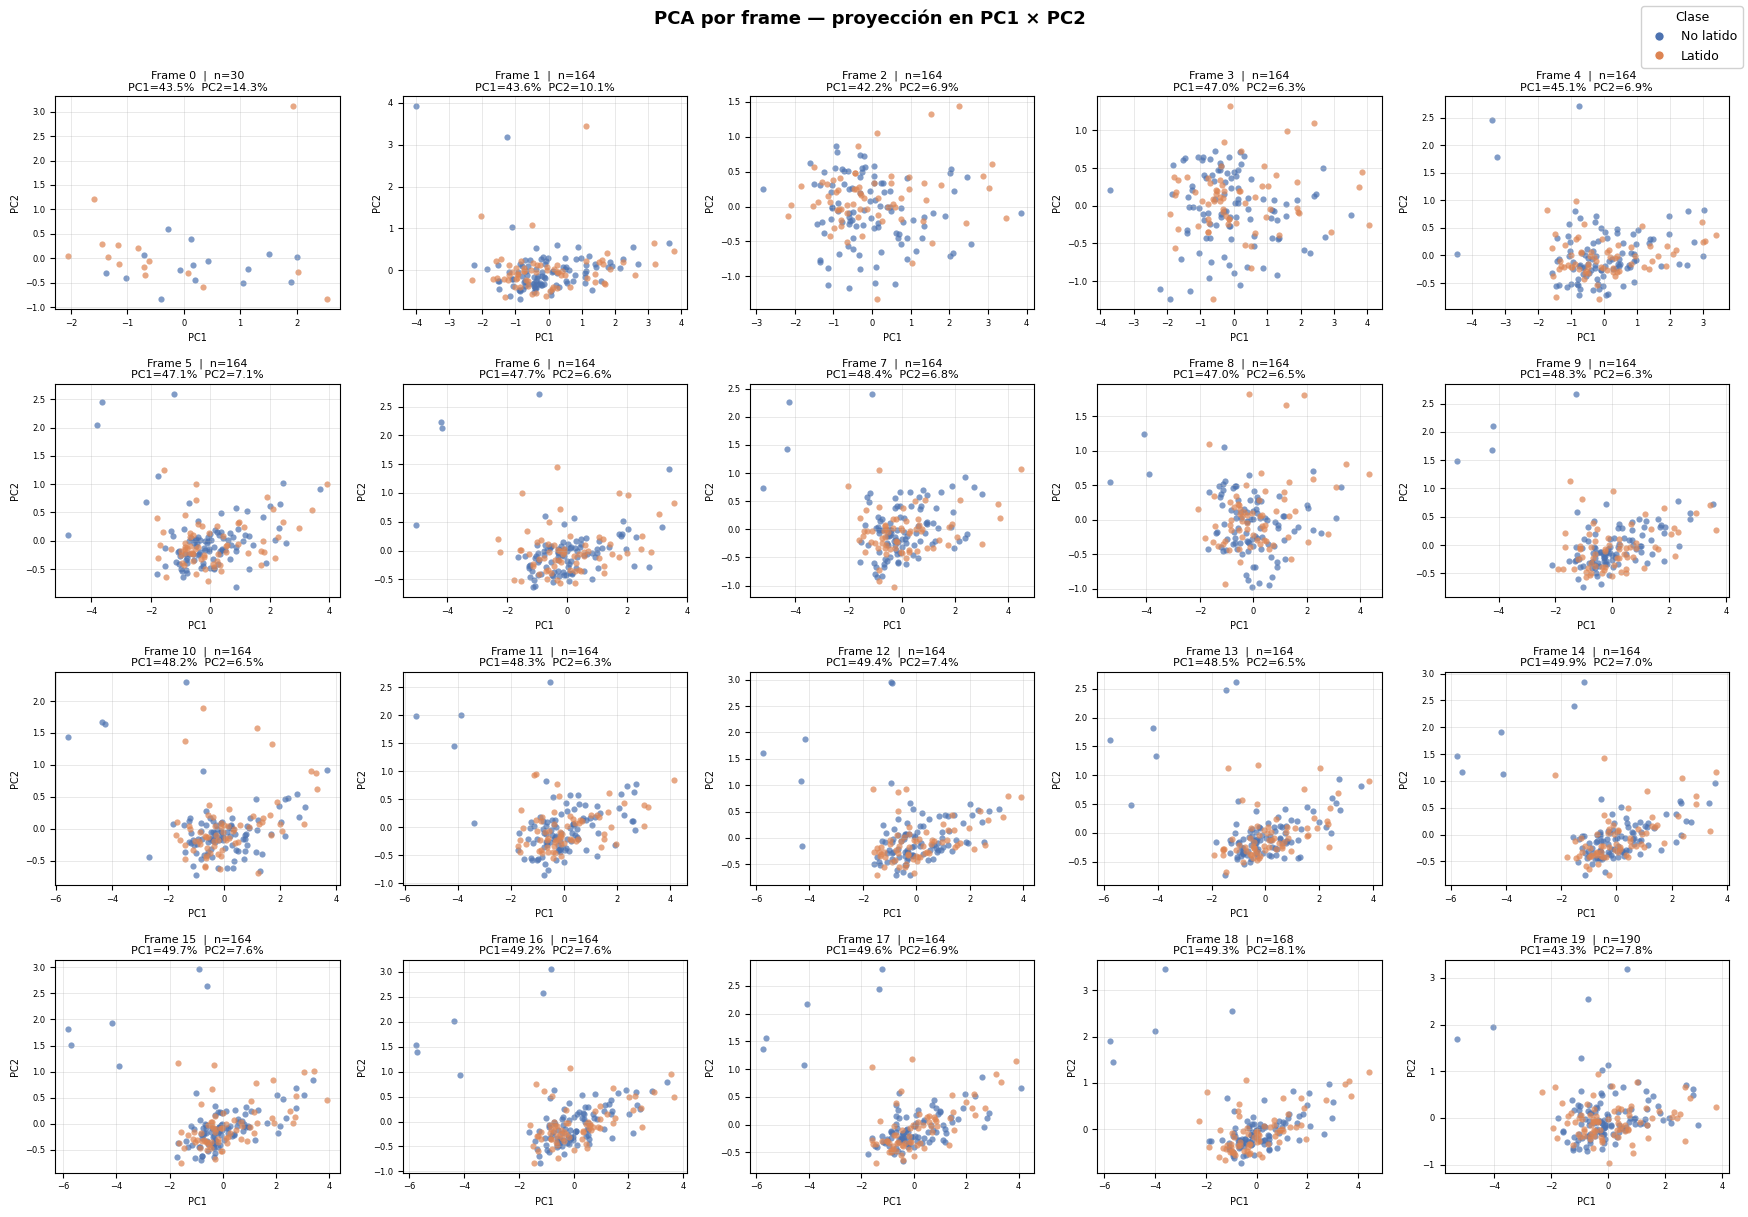

Guardado → pca_frames_grid.png


In [103]:
plot_pca_frames_grid(X_train, X_train_mask, y_train, frames_to_plot=list(range(20)), n_cols=5)

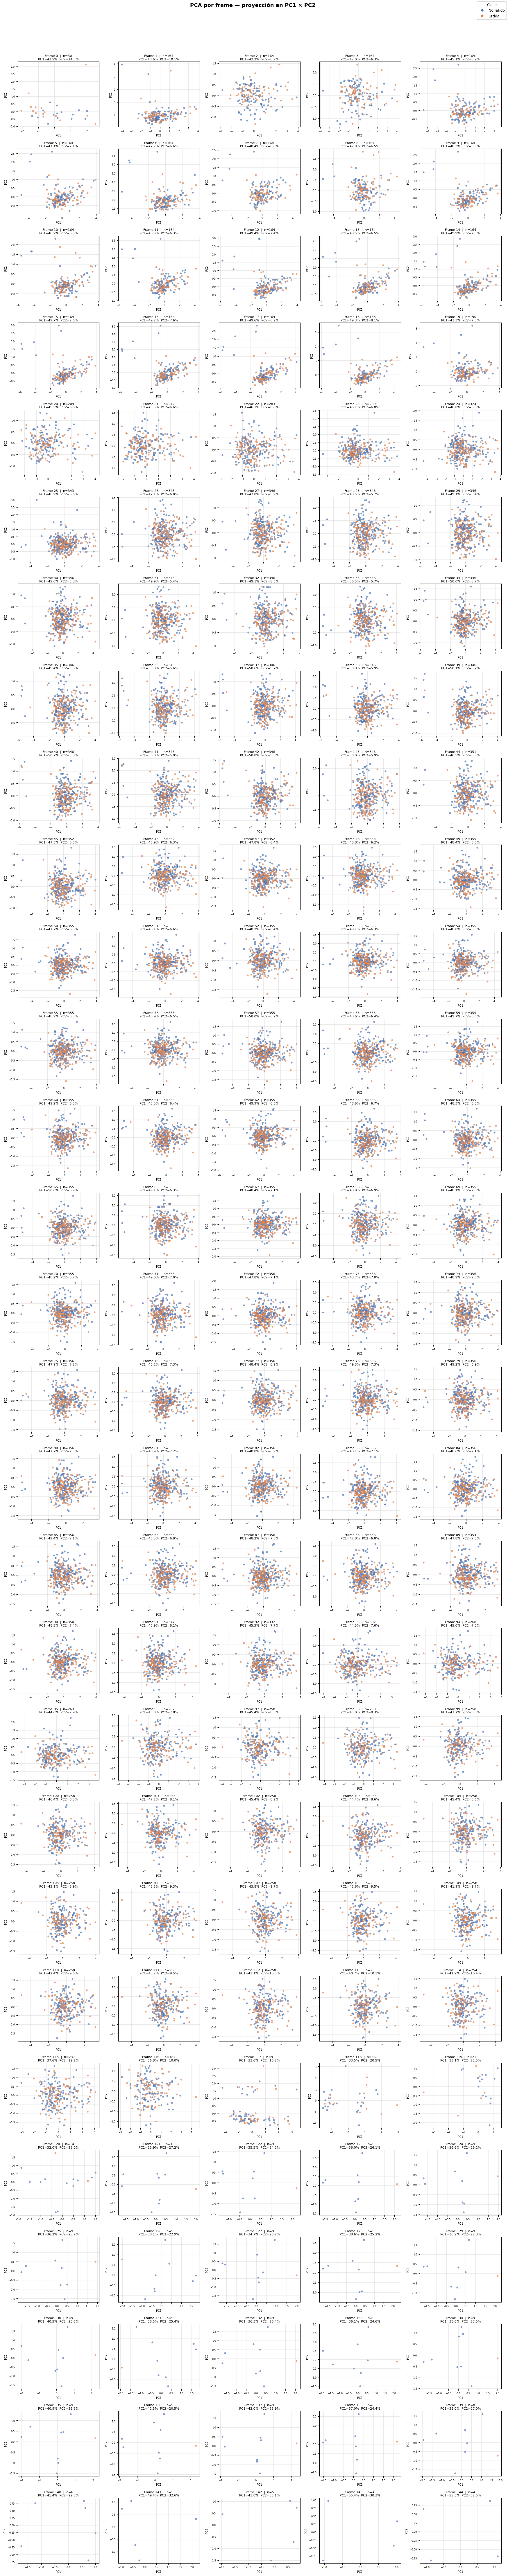

Guardado → pca_frames_grid214.png


In [108]:
plot_pca_frames_grid(X_train, X_train_mask, y_train, frames_to_plot=list(range(214)), n_cols=5, filename="pca_frames_grid214.png")